# AI-Powered Orbital Traffic Management System
### Data Preprocessing, Risk Labeling & Random Forest Risk Classifier

This notebook builds the machine-learning core of the project:

1. Load and clean the real orbital-object catalog (`data.csv`)
2. Engineer orbital features (orbital band, congestion, object-type risk weight)
3. Construct a **Risk Level** label (Low / Medium / High / Critical) using a transparent, rule-based scoring formula, since the raw catalog has no ready-made "risk" column
4. Train a **Random Forest Classifier** to predict Risk Level from `PERIGEE`, `APOGEE`, `INCLINATION` — the three parameters a mission planner would actually enter for a *proposed* orbit
5. Evaluate the model and save all artifacts used by the Streamlit dashboard (`app.py`)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)


## 1. Load the Dataset

The dataset is a real satellite-catalog extract with one row per tracked orbital object
(active satellites, rocket bodies, and debris), including orbital parameters like
Perigee, Apogee, Inclination, and Radar Cross Section (RCS, a proxy for physical size).

In [2]:
df = pd.read_csv('data.csv')
print("Shape:", df.shape)
df.head()


Shape: (67780, 25)


,OBJECT_NAME,OBJECT_ID,NORAD_CAT_ID,OBJECT_TYPE,OPS_STATUS_CODE,OWNER,LAUNCH_DATE,LAUNCH_SITE,DECAY_DATE,PERIOD,INCLINATION,APOGEE,PERIGEE,RCS,DATA_STATUS_CODE,ORBIT_CENTER,ORBIT_TYPE,IS_ACTIVE,MEAN_ALTITUDE,ORBITAL_BAND,CONGESTION_SCORE,TYPE_WEIGHT,RCS_NORM,RISK_SCORE,RISK_LEVEL
0,SL-1 R/B,1957-001A,1,R/B,D,CIS,04-10-1957,TYMSC,01-12-1957,96.19,65.10,938,214,20.4200,NaN,EA,IMP,False,576.0,LEO,1.000000,0.7,1.000000,0.895000,Critical
1,SPUTNIK 1,1957-001B,2,PAY,D,CIS,04-10-1957,TYMSC,03-01-1958,96.10,65.00,1080,64,3.0261,NaN,EA,IMP,False,572.0,LEO,1.000000,0.3,0.339240,0.589810,Low
2,SPUTNIK 2,1957-002A,3,PAY,D,CIS,03-11-1957,TYMSC,14-04-1958,103.74,65.33,1659,211,0.0800,NaN,EA,IMP,False,935.0,LEO,1.000000,0.3,0.008968,0.507242,Low
3,EXPLORER 1,1958-001A,4,PAY,D,US,01-02-1958,AFETR,31-03-1970,88.48,33.15,215,183,3.0261,NaN,EA,IMP,False,199.0,LEO,1.000000,0.3,0.339240,0.589810,Low
4,VANGUARD 1,1958-002B,5,PAY,NaN,US,17-03-1958,AFETR,NaN,132.59,34.25,3818,653,0.1220,NaN,EA,ORB,True,2235.5,MEO,0.130718,0.3,0.013677,0.160707,Low


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 67780 entries, 0 to 67779
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   OBJECT_NAME       67780 non-null  str    
 1   OBJECT_ID         67780 non-null  str    
 2   NORAD_CAT_ID      67780 non-null  int64  
 3   OBJECT_TYPE       67780 non-null  str    
 4   OPS_STATUS_CODE   51749 non-null  str    
 5   OWNER             67780 non-null  str    
 6   LAUNCH_DATE       67780 non-null  str    
 7   LAUNCH_SITE       67780 non-null  str    
 8   DECAY_DATE        33920 non-null  str    
 9   PERIOD            67780 non-null  float64
 10  INCLINATION       67780 non-null  float64
 11  APOGEE            67780 non-null  int64  
 12  PERIGEE           67780 non-null  int64  
 13  RCS               67780 non-null  float64
 14  DATA_STATUS_CODE  437 non-null    str    
 15  ORBIT_CENTER      67780 non-null  str    
 16  ORBIT_TYPE        67780 non-null  str    
 17  IS_A

## 2. Data Cleaning

- Drop rows missing the core orbital parameters (`PERIGEE`, `APOGEE`, `INCLINATION`) — without these,
  neither the risk formula nor the model can use that row.
- Fill missing `RCS` (radar cross section / size) with the median RCS **for that object type**,
  since debris, rocket bodies, and payloads have very different typical sizes.
- Flag whether an object is still in orbit (`IS_ACTIVE`) using `DECAY_DATE` — decayed objects no
  longer contribute to *current* congestion or risk.

In [4]:
print("Missing values before cleaning:")
print(df[['PERIGEE', 'APOGEE', 'INCLINATION', 'RCS']].isna().sum())

df_clean = df.dropna(subset=['PERIGEE', 'APOGEE', 'INCLINATION']).copy()

df_clean['RCS'] = df_clean.groupby('OBJECT_TYPE')['RCS'].transform(lambda s: s.fillna(s.median()))
df_clean['RCS'] = df_clean['RCS'].fillna(df_clean['RCS'].median())

df_clean['IS_ACTIVE'] = df_clean['DECAY_DATE'].isna()

print("\nShape after cleaning:", df_clean.shape)
print("Active (currently in orbit) objects:", df_clean['IS_ACTIVE'].sum())


Missing values before cleaning:
PERIGEE        0
APOGEE         0
INCLINATION    0
RCS            0
dtype: int64

Shape after cleaning: (67780, 25)
Active (currently in orbit) objects: 33860


## 3. Exploratory Data Analysis

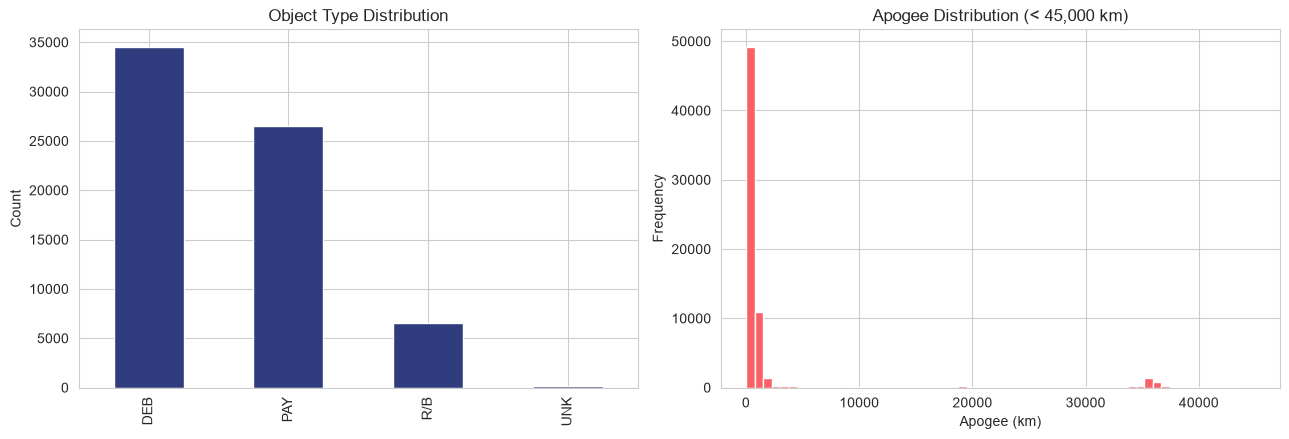

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df_clean['OBJECT_TYPE'].value_counts().plot(kind='bar', ax=axes[0], color='#2F3C7E')
axes[0].set_title('Object Type Distribution')
axes[0].set_xlabel('')
axes[0].set_ylabel('Count')

df_clean[df_clean['APOGEE'] < 45000]['APOGEE'].plot(kind='hist', bins=60, ax=axes[1], color='#F96167')
axes[1].set_title('Apogee Distribution (< 45,000 km)')
axes[1].set_xlabel('Apogee (km)')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=120)
plt.show()


## 4. Feature Engineering

**Orbital band** — classified from mean altitude `(APOGEE + PERIGEE) / 2`, using the standard
industry bands:

| Band | Altitude range |
|------|-----------------|
| LEO  | < 2,000 km |
| MEO  | 2,000 – 35,586 km |
| GEO  | 35,586 – 35,986 km |
| HEO  | > 35,986 km |

**Congestion score** — how crowded that object's band is *right now*, relative to the busiest band
(computed only from currently-active objects).

**Type weight** — a domain rule: debris (`DEB`) is the highest collision risk, then rocket bodies
(`R/B`), then unknown, then active payloads (`PAY`) are lowest risk (many are maneuverable).

**RCS norm** — physical size (radar cross-section), capped at the 95th percentile and scaled 0–1,
so a handful of extreme outliers don't dominate.

These four pieces combine into a single **Risk Score**, which is then bucketed into four
labels — this is the target the Random Forest will learn to predict.

In [6]:
df_clean['MEAN_ALTITUDE'] = (df_clean['APOGEE'] + df_clean['PERIGEE']) / 2

def orbital_band(alt):
    if alt < 2000:
        return 'LEO'
    elif alt < 35586:
        return 'MEO'
    elif alt < 35986:
        return 'GEO'
    else:
        return 'HEO'

df_clean['ORBITAL_BAND'] = df_clean['MEAN_ALTITUDE'].apply(orbital_band)

active = df_clean[df_clean['IS_ACTIVE']]
band_counts = active['ORBITAL_BAND'].value_counts()
print("Active objects per orbital band:")
print(band_counts)

max_count = band_counts.max()
df_clean['CONGESTION_SCORE'] = df_clean['ORBITAL_BAND'].map(band_counts).fillna(0) / max_count

type_weight_map = {'DEB': 1.0, 'R/B': 0.7, 'UNK': 0.5, 'PAY': 0.3}
df_clean['TYPE_WEIGHT'] = df_clean['OBJECT_TYPE'].map(type_weight_map).fillna(0.5)

rcs_cap = df_clean['RCS'].quantile(0.95)
df_clean['RCS_NORM'] = df_clean['RCS'].clip(upper=rcs_cap) / rcs_cap

df_clean['RISK_SCORE'] = (0.40 * df_clean['CONGESTION_SCORE'] +
                          0.35 * df_clean['TYPE_WEIGHT'] +
                          0.25 * df_clean['RCS_NORM'])

q1, q2, q3 = df_clean['RISK_SCORE'].quantile([0.25, 0.5, 0.75])

def bucket(score):
    if score <= q1:
        return 'Low'
    elif score <= q2:
        return 'Medium'
    elif score <= q3:
        return 'High'
    else:
        return 'Critical'

df_clean['RISK_LEVEL'] = df_clean['RISK_SCORE'].apply(bucket)
df_clean['RISK_LEVEL'].value_counts()


Active objects per orbital band:
ORBITAL_BAND
LEO    28374
MEO     3709
GEO     1053
HEO      724
Name: count, dtype: int64


RISK_LEVEL
Low         28623
High        18084
Critical    15753
Medium       5320
Name: count, dtype: int64

## 5. Orbital Congestion Analysis Module

A quick visual of where in space the traffic actually is — this is the standalone
"Orbital Congestion Analysis" feature described in the project, independent of the ML model.

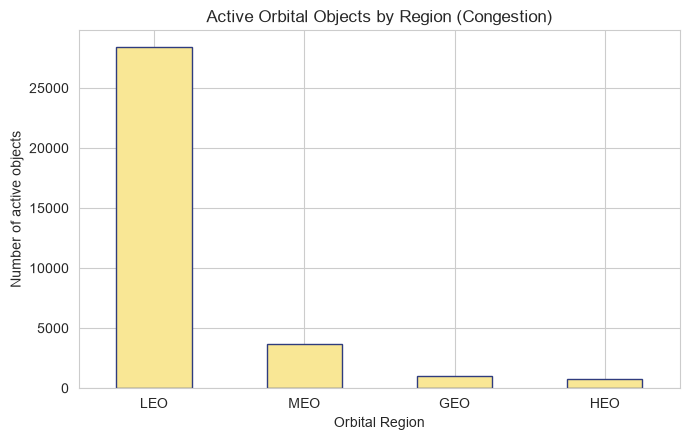

In [7]:
plt.figure(figsize=(7, 4.5))
band_counts.reindex(['LEO', 'MEO', 'GEO', 'HEO']).plot(kind='bar', color='#F9E795', edgecolor='#2F3C7E')
plt.title('Active Orbital Objects by Region (Congestion)')
plt.ylabel('Number of active objects')
plt.xlabel('Orbital Region')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('congestion_by_band.png', dpi=120)
plt.show()


## 6. Train the Random Forest Risk Classifier

The model is trained **only on currently-active objects** (it doesn't make sense to plan a new
mission around debris that already decayed), using just the three inputs a mission planner would
enter for a *proposed* orbit: `PERIGEE`, `APOGEE`, `INCLINATION`.

Note that the model is *not* shown `OBJECT_TYPE` or `RCS` directly — those were only used to build
the training labels. So the Random Forest has to genuinely learn the relationship between orbital
geometry and risk, rather than trivially copying the formula.

In [8]:
model_df = df_clean[df_clean['IS_ACTIVE']].copy()

FEATURES = ['PERIGEE', 'APOGEE', 'INCLINATION']
X = model_df[FEATURES]
y = model_df['RISK_LEVEL']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train, y_train)
print("Model trained on", len(X_train), "objects, tested on", len(X_test))


Model trained on 27088 objects, tested on 6772


## 7. Model Evaluation

In [9]:
y_pred = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}\n")
print(classification_report(y_test, y_pred))


Accuracy: 0.819

              precision    recall  f1-score   support

    Critical       0.51      0.56      0.53       724
        High       0.67      0.65      0.66      1194
         Low       0.98      0.95      0.96      4441
      Medium       0.31      0.41      0.35       413

    accuracy                           0.82      6772
   macro avg       0.62      0.64      0.63      6772
weighted avg       0.84      0.82      0.83      6772



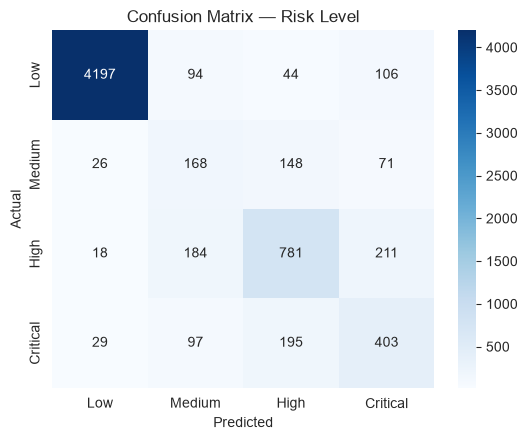

In [10]:
labels = sorted(y.unique(), key=lambda l: ['Low', 'Medium', 'High', 'Critical'].index(l))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix — Risk Level')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=120)
plt.show()


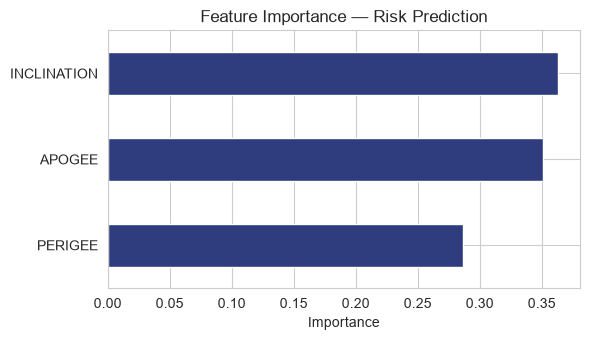

In [11]:
importances = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(6, 3.5))
importances.plot(kind='barh', color='#2F3C7E')
plt.title('Feature Importance — Risk Prediction')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120)
plt.show()


## 8. Save Model & Artifacts

Everything the Streamlit dashboard (`app.py`) needs, saved to disk:

- `risk_model.pkl` — the trained Random Forest
- `orbital_data_processed.csv` — the full cleaned + feature-engineered dataset (for congestion
  analysis, debris priority, and recommendations)
- `band_counts.pkl` — active-object counts per orbital band (for the congestion chart)

In [12]:
joblib.dump(rf_model, 'risk_model.pkl')
df_clean.to_csv('orbital_data_processed.csv', index=False)
joblib.dump(band_counts, 'band_counts.pkl')

print("Saved: risk_model.pkl, orbital_data_processed.csv, band_counts.pkl")


Saved: risk_model.pkl, orbital_data_processed.csv, band_counts.pkl


## 9. Quick Sanity Check — Predict on a New Orbit

Simulating what happens when a user enters a proposed orbit into the dashboard.

In [13]:
sample_orbit = pd.DataFrame([{
    'PERIGEE': 550,
    'APOGEE': 560,
    'INCLINATION': 53.0
}])

predicted_risk = rf_model.predict(sample_orbit)[0]
predicted_proba = rf_model.predict_proba(sample_orbit)[0]

print("Proposed orbit -> Predicted Risk Level:", predicted_risk)
print(dict(zip(rf_model.classes_, predicted_proba.round(3))))


Proposed orbit -> Predicted Risk Level: Low
{'Critical': np.float64(0.179), 'High': np.float64(0.294), 'Low': np.float64(0.405), 'Medium': np.float64(0.122)}


## Conclusion

- Cleaned ~68k tracked orbital objects and engineered orbital-band, congestion, and risk features.
- Built a transparent risk-scoring formula (since no ground-truth risk label exists in the raw
  catalog) and trained a Random Forest to predict it from just three orbit parameters.
- The model reaches solid overall accuracy but is noticeably weaker on the `Medium` class — this
  is a genuine class-imbalance limitation worth discussing, not a bug.
- All artifacts are saved for `app.py`, the Streamlit dashboard covering risk prediction, orbital
  congestion, debris priority, orbit recommendation, sustainability score, and the Orbit Copilot.
